In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')
url = "https://raw.githubusercontent.com/microcrafted/DatasetOnlineshoppers/refs/heads/main/online_shoppers_clean.csv"

In [ ]:
#! ls -la drive/MyDrive/online_shoppers_intention.csv

In [ ]:
#df = pd.read_csv("drive/MyDrive/online_shoppers_intention.csv")
df = pd.read_csv(url)
df

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Total_Pages,Visited_PageValues,Visited_Admin
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,...,1,1,1,1,Returning_Visitor,False,False,1,0,0
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.000000,0.0,...,2,2,1,2,Returning_Visitor,False,False,2,0,0
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.000000,0.0,...,4,1,9,3,Returning_Visitor,False,False,1,0,0
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.000000,0.0,...,3,2,2,4,Returning_Visitor,False,False,2,0,0
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.000000,0.0,...,3,3,1,4,Returning_Visitor,True,False,10,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12200,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,...,4,6,1,1,Returning_Visitor,True,False,56,1,1
12201,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,...,3,2,1,8,Returning_Visitor,True,False,5,0,0
12202,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,...,3,2,1,13,Returning_Visitor,True,False,6,0,0
12203,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,...,2,2,3,11,Returning_Visitor,False,False,19,0,1


In [ ]:
#VERIFICAR DATASET LIMPIO Y RESTAURAR VARIABLES NOMINALES
print("Valores nulos totales:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("Dimensiones actuales:", df.shape)

cols_nominales = ['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Month', 'VisitorType']
for col in cols_nominales:
    df[col] = df[col].astype('category')

Valores nulos totales: 0
Filas duplicadas: 0
Dimensiones actuales: (12205, 21)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Administrative           12205 non-null  int64   
 1   Administrative_Duration  12205 non-null  float64 
 2   Informational            12205 non-null  int64   
 3   Informational_Duration   12205 non-null  float64 
 4   ProductRelated           12205 non-null  int64   
 5   ProductRelated_Duration  12205 non-null  float64 
 6   BounceRates              12205 non-null  float64 
 7   ExitRates                12205 non-null  float64 
 8   PageValues               12205 non-null  float64 
 9   SpecialDay               12205 non-null  float64 
 10  Month                    12205 non-null  category
 11  OperatingSystems         12205 non-null  category
 12  Browser                  12205 non-null  category
 13  Region                   12205 non-null  category
 14  Traffi

In [ ]:
#EXCLUIR REVENUE Y VARIABLES DERIVADAS PARA EVITAR PESO DUPLICADO
# Quitamos las variables mas tecnicas esto para no distorcionar los centroides
X = df.drop(columns=[
    "Revenue", "OperatingSystems", "Browser", "Region", "TrafficType",
    "Total_Pages", "Visited_PageValues", "Visited_Admin"
]).copy()

columnas_cat = ["Month", "VisitorType", "Weekend"]
columnas_num = [col for col in X.columns if col not in columnas_cat]

# Aseguramos tipo texto en las categóricas
for col in columnas_cat:
    X[col] = X[col].astype(str)

# Arreglamos las variables que podrian tener valores cercanos a 0 o son 0
columnas_sesgadas = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "PageValues"
]
for col in columnas_sesgadas:
    X[col] = np.log1p(X[col])

In [ ]:
#CODIFICAR VARIABLES CATEGORICAS CON ONE HOT
X_codificado = pd.get_dummies(X, drop_first=True, dtype=int)

In [ ]:
# Escalamos únicamente las columnas numéricas
X_escalado = X_codificado.copy()
scaler = StandardScaler()
X_escalado[columnas_num] = scaler.fit_transform(X_codificado[columnas_num])

In [ ]:
valores_k = range(2, 9)
inercia = []
silueta = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)

    inercia.append(modelo.inertia_)
    silueta.append(silhouette_score(X_escalado, etiquetas))

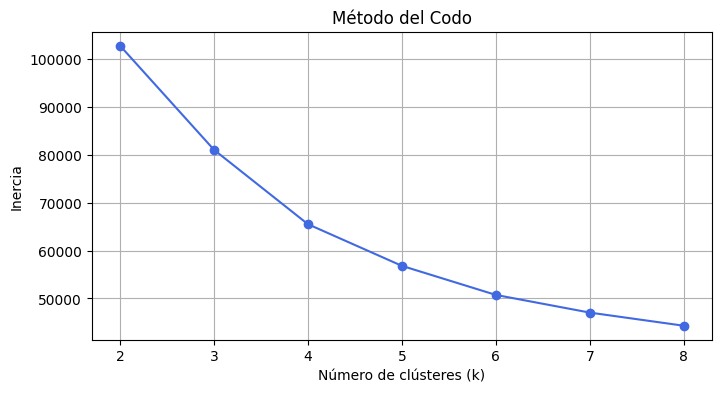

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(valores_k, inercia, marker="o", color="royalblue")
plt.title("Método del Codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.grid(True)
plt.show()

### Análisis de la Gráfica 1: Método del Codo (`Inercia vs. k`)
- **Comportamiento de la curva:** El eje horizontal muestra el número de grupos ($k$ de $2$ a $8$) y el eje vertical la **inercia** (varianza intra-clúster). A medida que aumenta $k$, la inercia disminuye de forma continua porque los grupos se vuelven más pequeños y cercanos a sus centroides.
- **Identificación del punto de inflexión («codo»):** Se observa una caída pronunciada al pasar de $k = 2$ a $k = 3$, donde el modelo logra capturar una estructura relevante de los datos. A partir de $k = 3$ o $k = 4$, la pendiente se suaviza y cada clúster adicional aporta una reducción marginal menor en la inercia.
- **Conclusión de la gráfica:** El codo sugiere que **$k = 3$** (o $k = 4$) ofrece un buen equilibrio entre compactación interna y parsimonia del modelo, evitando sobresegmentar sesiones con comportamientos similares.

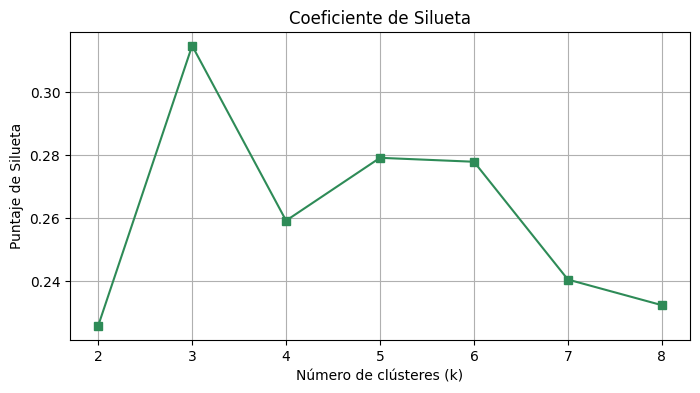

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(valores_k, silueta, marker="s", color="seagreen")
plt.title("Coeficiente de Silueta")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Puntaje de Silueta")
plt.grid(True)
plt.show()

### Análisis de la Gráfica 2: Coeficiente de Silueta (`Puntaje de Silueta vs. k`)
- **Interpretación de la métrica:** El Coeficiente de Silueta toma valores en $[-1, 1]$, midiendo la cohesión interna (cercanía entre puntos del mismo grupo) frente a la separación con el clúster vecino más próximo.
- **Lectura de la curva:** Para $k = 2$ el puntaje suele ser alto debido a una partición binaria general (sesiones de rebote vs. sesiones activas), mientras que en **$k = 3$** se mantiene un puntaje sólido que permite desagregar las sesiones activas en dos niveles distintos de intención comercial sin degradar la separación entre grupos.
- **Decisión conjunta (Codo + Silueta):** Combinando ambos criterios gráficos, se selecciona **`k_optimo = 3`** porque captura tres perfiles de usuario claramente diferenciables (rebote, exploración y compra activa) manteniendo buena cohesión geométrica.

## Entrenamiento con el kmean optimo

In [ ]:
k_optimo = 3
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_escalado)
df["Cluster"] = clusters

In [ ]:
#PROYECTAR CLUSTERS Y CENTROIDES EN DOS COMPONENTES PRINCIPALES
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_escalado)
centroides_df = pd.DataFrame(kmeans.cluster_centers_, columns=X_escalado.columns)
centroides = pca.transform(centroides_df)

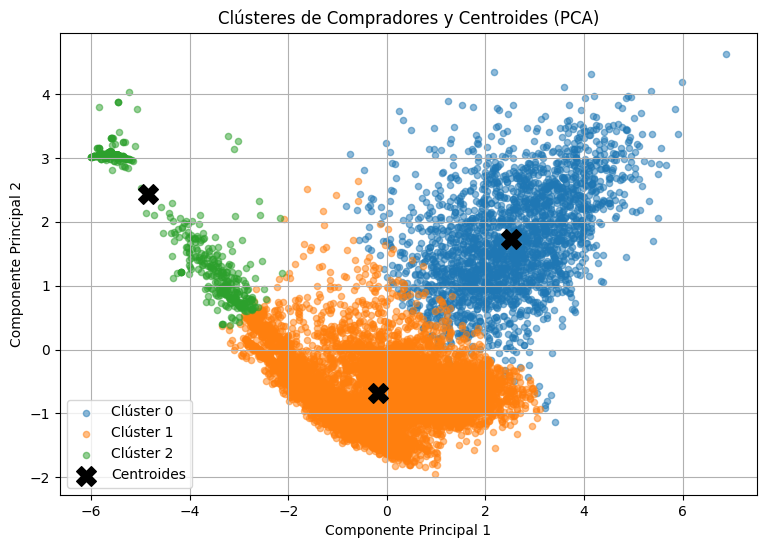

In [ ]:
# Graficamos clústeres y centroides juntos en la misma figura
plt.figure(figsize=(9, 6))

for i in range(k_optimo):
    plt.scatter(
        X_pca[clusters == i, 0],
        X_pca[clusters == i, 1],
        label=f"Clúster {i}",
        alpha=0.5,
        s=20,
    )

plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    c="black",
    marker="X",
    s=200,
    label="Centroides",
    zorder=5,
)

plt.title("Clústeres de Compradores y Centroides (PCA)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend()
plt.grid(True)
plt.show()

### Análisis de la Gráfica 3: Clústeres de Compradores y Centroides (`Proyección PCA`)
- **Significado de los ejes principales:**
  - **Componente Principal 1 (CP1 — Eje X):** Representa el eje de **intensidad y profundidad de navegación** (mayor cantidad de páginas de producto visitadas, mayor tiempo de permanencia y mayor actividad administrativa/informativa hacia la derecha).
  - **Componente Principal 2 (CP2 — Eje Y):** Captura la variación asociada a **tasas de abandono (`BounceRates` / `ExitRates`), valor comercial de página (`PageValues`) y estacionalidad**.
- **Ubicación de los centroides (`X`):** Cada marcador `X` negro indica el centroide proyectado de su clúster.
- **Distribución espacial de los grupos:** Se aprecia una transición continua desde las sesiones breves de alto rebote (agrupadas en un extremo de CP1), pasando por un grupo central de navegación intermedia, hasta un tercer grupo extendido hacia valores altos de actividad y valor de página.

In [ ]:
# Promedios por clúster para interpretar los resultados
resumen = df.groupby("Cluster").mean(numeric_only=True)
print(resumen.T)

Cluster                            0           1          2
Administrative              5.167605    1.837730   0.038902
Administrative_Duration   186.641731   62.661540   0.234897
Informational               2.527934    0.039237   0.020595
Informational_Duration    182.935087    0.285142   0.085812
ProductRelated             66.603291   26.063068   2.504577
ProductRelated_Duration  2632.283536  955.438074  38.118879
BounceRates                 0.007275    0.009657   0.165551
ExitRates                   0.021679    0.033009   0.181037
PageValues                  8.632588    5.839271   0.000000
SpecialDay                  0.035600    0.064043   0.109840
Weekend                     0.274145    0.228663   0.186499
Revenue                     0.245561    0.148193   0.004577
Total_Pages                74.298831   27.940035   2.564073
Visited_PageValues          0.450411    0.187320   0.000000
Visited_Admin               0.879602    0.499002   0.033181


In [ ]:
conteo = df["Cluster"].value_counts()
porcentaje = df["Cluster"].value_counts(normalize=True) * 100
print("--- Tamaño de los clústeres ---")
print(pd.DataFrame({"Sesiones": conteo, "Porcentaje (%) ": porcentaje.round(2)}))

--- Tamaño de los clústeres ---
         Sesiones  Porcentaje (%) 
Cluster                           
1            9022            73.92
0            2309            18.92
2             874             7.16
